In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [2]:
#Load the dataset

DATA_PATH = Path("../data/raw/customer_churn.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


In [3]:
#Understanding the dataset

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [6]:
df.describe().T # Generating descriptive statistics

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [8]:
#Check missing values
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Count", ascending=False)

missing_summary

,Missing Count,Missing Percentage


In [9]:
#Check for duplicate records

print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 0


In [10]:
df["Churn"].value_counts() # Examining the target distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
).round(2)

print(churn_percentage)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


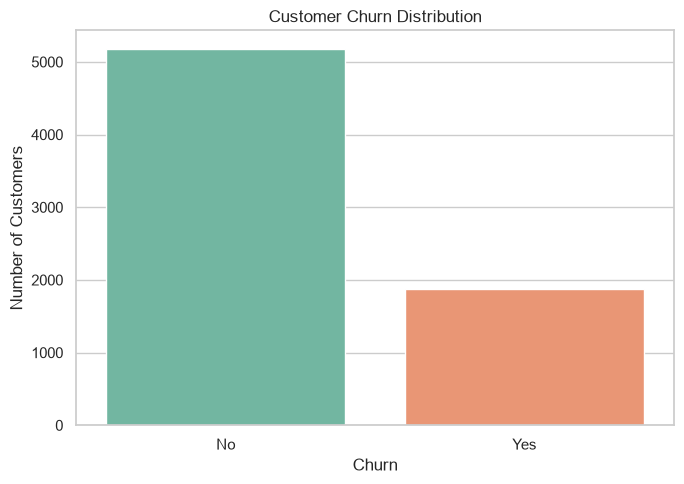

In [12]:
#Visualize the target distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [13]:
#Investigate the data quality -- Examine the total charges

print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nBlank strings:")
print(df["TotalCharges"].astype(str).str.strip().eq("").sum())

print("\nFirst 15 values:")
print(df["TotalCharges"].head(15).tolist())


TotalCharges data type:
str

Blank strings:
11

First 15 values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05']


In [14]:
#Investigate the affected rows

blank_total_charges = df[
    df["TotalCharges"].astype(str).str.strip().eq("")
]

blank_total_charges[
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [16]:
# Identify categorical columns, including string columns
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns

# Display the unique values and frequencies of each categorical column
for column in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {column}")
    print(f"Unique values: {df[column].nunique(dropna=False)}")
    print(df[column].value_counts(dropna=False).head(10))


Column: customerID
Unique values: 7043
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64

Column: gender
Unique values: 2
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Partner
Unique values: 2
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Unique values: 2
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: PhoneService
Unique values: 2
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Column: MultipleLines
Unique values: 3
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: InternetService
Unique values: 3
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: OnlineSecurity
Unique values: 3
OnlineSecurity
No                  

In [17]:
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns

categorical_summary = pd.DataFrame({
    "Unique Values": df[categorical_columns].nunique(),
    "Missing Values": df[categorical_columns].isnull().sum()
})

categorical_summary

,Unique Values,Missing Values
customerID,7043,0
gender,2,0
Partner,2,0
Dependents,2,0
PhoneService,2,0
MultipleLines,3,0
InternetService,3,0
OnlineSecurity,3,0
OnlineBackup,3,0
DeviceProtection,3,0
